# 第 3 课：采样陷阱与实战模板（约 30 分钟）

目标：避开 FFT 工程中最常见的坑，并拿到可替换真实图片的处理模板。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["axes.grid"] = True
# 优先使用常见中文字体；最后的 DejaVu Sans 保证数字和英文正常显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def show_images(images, titles, cmap="gray"):
    """并排显示若干幅图像。"""
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4))
    axes = np.atleast_1d(axes)
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 1. 混叠：采得不够密会“看见假频率”

奈奎斯特原则：采样率至少要大于信号最高频率的 2 倍。图像中同理：过密纹理被像素网格错误记录，会产生摩尔纹。


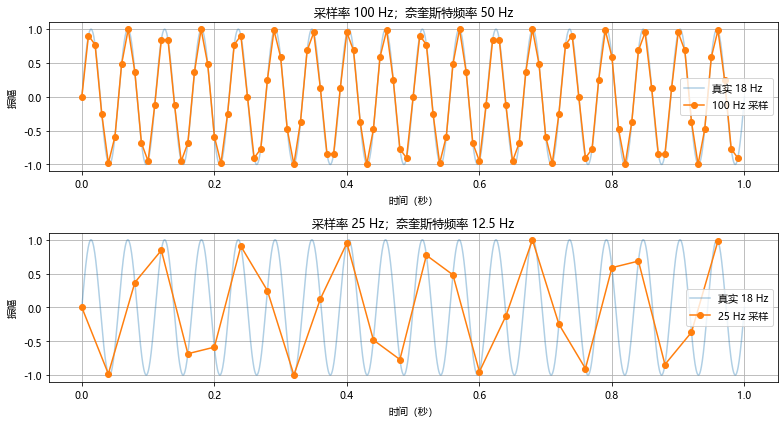

In [2]:
true_frequency = 18
duration = 1

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for ax, fs in zip(axes, [100, 25]):
    t_dense = np.linspace(0, duration, 2000)
    t_sample = np.arange(0, duration, 1 / fs)
    ax.plot(t_dense, np.sin(2*np.pi*true_frequency*t_dense), alpha=0.35, label="真实 18 Hz")
    ax.plot(t_sample, np.sin(2*np.pi*true_frequency*t_sample), "o-", label=f"{fs} Hz 采样")
    ax.set_title(f"采样率 {fs} Hz；奈奎斯特频率 {fs/2:g} Hz")
    ax.set_xlabel("时间（秒）"); ax.set_ylabel("振幅"); ax.legend()
plt.tight_layout(); plt.show()


100 Hz 足以表达 18 Hz；25 Hz 的奈奎斯特频率只有 12.5 Hz，18 Hz 会伪装成更低频率。图像缩小时先做抗混叠滤波，正是为了避免这个问题。


## 2. 频谱泄漏：观察窗口装不下完整周期

FFT 默认截取片段首尾可以无缝相接。如果首尾断裂，这个跳变会制造大量额外频率。窗函数让两端平滑收敛，减少泄漏，但会让峰变宽。


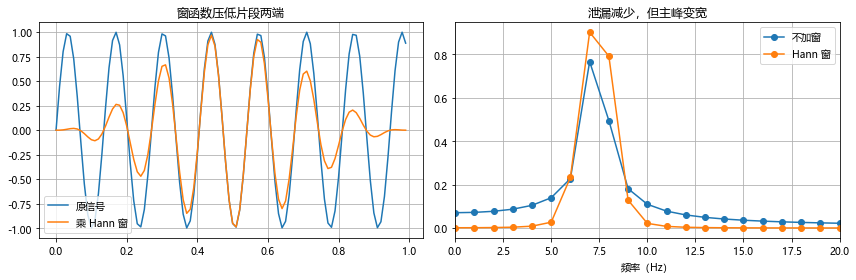

In [3]:
fs = 100
n = 100
t = np.arange(n) / fs
signal = np.sin(2 * np.pi * 7.4 * t)  # 1 秒内不是整数个周期
window = np.hanning(n)

freq = np.fft.rfftfreq(n, 1/fs)
raw_spec = 2*np.abs(np.fft.rfft(signal))/n
win_spec = 2*np.abs(np.fft.rfft(signal*window))/np.sum(window)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(t, signal, label="原信号")
axes[0].plot(t, signal*window, label="乘 Hann 窗")
axes[0].set_title("窗函数压低片段两端"); axes[0].legend()
axes[1].plot(freq, raw_spec, "o-", label="不加窗")
axes[1].plot(freq, win_spec, "o-", label="Hann 窗")
axes[1].set_xlim(0, 20); axes[1].set_title("泄漏减少，但主峰变宽")
axes[1].set_xlabel("频率（Hz）"); axes[1].legend()
plt.tight_layout(); plt.show()


## 3. 对图像做 FFT 的通用模板

把下面的 `image_path` 改成自己的图片路径。彩色图像先转灰度是为了学习方便；真实项目也可以分别处理 RGB 通道，或只处理亮度通道。


未找到 your_image.png，改用合成示例；替换 image_path 即可处理自己的图。


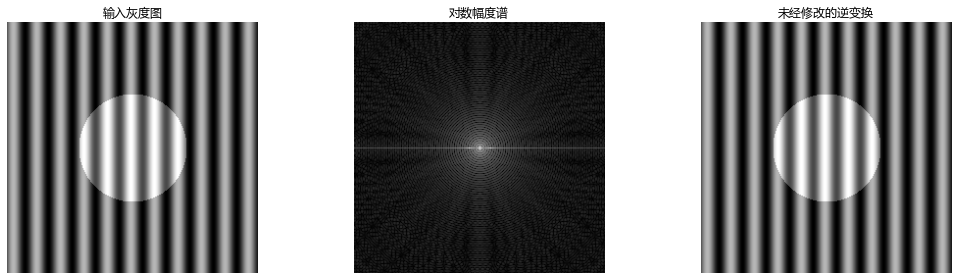

重建最大绝对误差： 4.440892098500626e-16


In [4]:
from pathlib import Path
from PIL import Image

image_path = Path("your_image.png")

if image_path.exists():
    image = np.asarray(Image.open(image_path).convert("L"), dtype=float) / 255.0
    print("已载入：", image_path, "尺寸：", image.shape)
else:
    print("未找到 your_image.png，改用合成示例；替换 image_path 即可处理自己的图。")
    n = 256
    yy, xx = np.mgrid[:n, :n]
    image = 0.35 + 0.25*np.sin(2*np.pi*xx/24) + 0.2*((xx-128)**2+(yy-128)**2 < 55**2)

F = np.fft.fftshift(np.fft.fft2(image))
spectrum_for_display = np.log1p(np.abs(F))
reconstructed = np.real(np.fft.ifft2(np.fft.ifftshift(F)))

show_images([image, spectrum_for_display, reconstructed],
            ["输入灰度图", "对数幅度谱", "未经修改的逆变换"])
print("重建最大绝对误差：", np.max(np.abs(image - reconstructed)))


## 4. 可复用滤波函数

接口设计：输入二维灰度图和掩膜，返回结果。掩膜必须与图像同尺寸，值通常在 0～1。


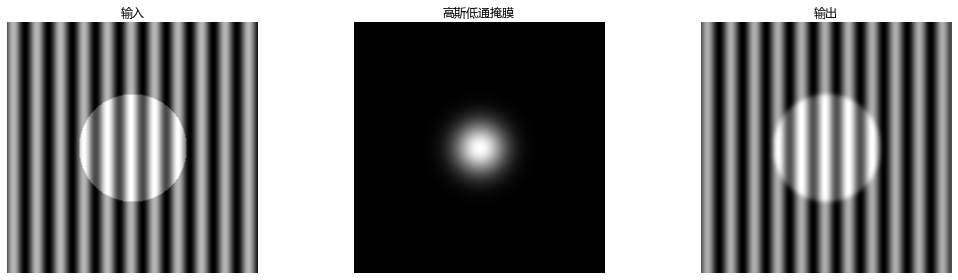

In [5]:
def fft_filter(image, mask):
    """使用给定的中心化频域掩膜过滤二维灰度图。"""
    if image.ndim != 2:
        raise ValueError("image 必须是二维灰度图")
    if image.shape != mask.shape:
        raise ValueError("mask 尺寸必须与 image 一致")
    F = np.fft.fftshift(np.fft.fft2(image))
    result = np.fft.ifft2(np.fft.ifftshift(F * mask))
    return np.real(result)

def gaussian_low_pass_mask(shape, sigma):
    h, w = shape
    y, x = np.mgrid[:h, :w]
    distance_sq = (x - w//2)**2 + (y - h//2)**2
    return np.exp(-distance_sq / (2*sigma**2))

mask = gaussian_low_pass_mask(image.shape, sigma=18)
filtered = fft_filter(image, mask)
show_images([image, mask, filtered], ["输入", "高斯低通掩膜", "输出"])


## 5. 最终检查清单

拿到一个真实图像频域任务时，按顺序问：

1. 我想删掉的是慢变化、高频细节，还是特定周期干扰？
2. 图像是否需要先转灰度/亮度通道？
3. 是否正确使用 `fftshift` 和 `ifftshift`？
4. 显示频谱时是否用了 `log1p(abs(F))`，处理时是否保留复数 `F`？
5. 掩膜是否中心对称、尺寸一致？
6. 硬截止是否导致振铃？
7. 结果是否用客观指标和原图对比，而不只是“看起来不错”？


# 两小时后你应当能解释

- 傅里叶变换：把图像从“每个位置多亮”转换为“各种空间变化模式有多强”；
- 二维频谱中心是低频，外侧是高频，方向表示变化方向；
- 低通、高通、陷波本质上都是给频谱乘一个掩膜；
- 逆变换能回到图像，但必须保留幅度和相位；
- 实际效果受采样、混叠、泄漏、截止方式影响。

如果这些话你能结合 Notebook 中的图解释出来，就已经达到工程入门目标。
